In [44]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sb

from sklearn.model_selection import train_test_split
from sklearn.metrics import ConfusionMatrixDisplay, RocCurveDisplay, confusion_matrix
from sklearn.ensemble import GradientBoostingClassifier

In [45]:
dataset = pd.read_csv('../data/heart_failure/heart_failure_clinical_records_dataset.csv')
dataset.head()

,age,anaemia,creatinine_phosphokinase,diabetes,ejection_fraction,high_blood_pressure,platelets,serum_creatinine,serum_sodium,sex,smoking,time,DEATH_EVENT
0,75.0,0,582,0,20,1,265000.00,1.9,130,1,0,4,1
1,55.0,0,7861,0,38,0,263358.03,1.1,136,1,0,6,1
2,65.0,0,146,0,20,0,162000.00,1.3,129,1,1,7,1
3,50.0,1,111,0,20,0,210000.00,1.9,137,1,0,7,1
4,65.0,1,160,1,20,0,327000.00,2.7,116,0,0,8,1


In [46]:
features = dataset.drop('DEATH_EVENT', axis=1)
targets = dataset['DEATH_EVENT']

features_trainval, features_test, targets_trainval, targets_test = \
    train_test_split(features, targets, test_size=0.4, stratify=targets)

features_test_male = features_test[features_test['sex']==1]
targets_test_male = targets_test.loc[features_test_male.index]
features_test_female = features_test[features_test['sex']==0]
targets_test_female = targets_test.loc[features_test_female.index]

In [47]:
gb1 = GradientBoostingClassifier()
gb1.fit(features_trainval, targets_trainval)

,"loss loss: {'log_loss', 'exponential'}, default='log_loss'The loss function to be optimized. 'log_loss' refers to binomial andmultinomial deviance, the same as used in logistic regression.It is a good choice for classification with probabilistic outputs.For loss 'exponential', gradient boosting recovers the AdaBoost algorithm.",'log_loss'
,"learning_rate learning_rate: float, default=0.1Learning rate shrinks the contribution of each tree by `learning_rate`.There is a trade-off between learning_rate and n_estimators.Values must be in the range `[0.0, inf)`.For an example of the effects of this parameter and its interaction with``subsample``, see:ref:`sphx_glr_auto_examples_ensemble_plot_gradient_boosting_regularization.py`.",0.1
,"n_estimators n_estimators: int, default=100The number of boosting stages to perform. Gradient boostingis fairly robust to over-fitting so a large number usuallyresults in better performance.Values must be in the range `[1, inf)`.",100
,"subsample subsample: float, default=1.0The fraction of samples to be used for fitting the individual baselearners. If smaller than 1.0 this results in Stochastic GradientBoosting. `subsample` interacts with the parameter `n_estimators`.Choosing `subsample < 1.0` leads to a reduction of varianceand an increase in bias.Values must be in the range `(0.0, 1.0]`.",1.0
,"criterion criterion: {'friedman_mse', 'squared_error'}, default='friedman_mse'This parameter has no effect... versionadded:: 0.18.. deprecated:: 1.9 `criterion` is deprecated and will be removed in 1.11.",'deprecated'
,"min_samples_split min_samples_split: int or float, default=2The minimum number of samples required to split an internal node:- If int, values must be in the range `[2, inf)`.- If float, values must be in the range `(0.0, 1.0]` and `min_samples_split` will be `ceil(min_samples_split * n_samples)`... versionchanged:: 0.18 Added float values for fractions.",2
,"min_samples_leaf min_samples_leaf: int or float, default=1The minimum number of samples required to be at a leaf node.A split point at any depth will only be considered if it leaves atleast ``min_samples_leaf`` training samples in each of the left andright branches. This may have the effect of smoothing the model,especially in regression.- If int, values must be in the range `[1, inf)`.- If float, values must be in the range `(0.0, 1.0)` and `min_samples_leaf` will be `ceil(min_samples_leaf * n_samples)`... versionchanged:: 0.18 Added float values for fractions.",1
,"min_weight_fraction_leaf min_weight_fraction_leaf: float, default=0.0The minimum weighted fraction of the sum total of weights (of allthe input samples) required to be at a leaf node. Samples haveequal weight when sample_weight is not provided.Values must be in the range `[0.0, 0.5]`.",0.0
,"max_depth max_depth: int or None, default=3Maximum depth of the individual regression estimators. The maximumdepth limits the number of nodes in the tree. Tune this parameterfor best performance; the best value depends on the interactionof the input variables. If None, then nodes are expanded untilall leaves are pure or until all leaves contain less thanmin_samples_split samples.If int, values must be in the range `[1, inf)`.",3
,"min_impurity_decrease min_impurity_decrease: float, default=0.0A node will be split if this split induces a decrease of the impuritygreater than or equal to this value.Values must be in the range `[0.0, inf)`.The weighted impurity decrease equation is the following:: N_t / N * (impurity - N_t_R / N_t * right_impurity - N_t_L / N_t * left_impurity)where ``N`` is the total number of samples, ``N_t`` is the number ofsamples at the current node, ``N_t_L`` is the number of samples in theleft child, and ``N_t_R`` is the number of samples in the right child.``N``, ``N_t``, ``N_t_R`` and ``N_t_L`` all refer to the weighted sum,if ``sample_weight`` is passed... versionadded:: 0.19",0.0
,"init init: estimator or 'zero', default=NoneAn estimator object that is used to co

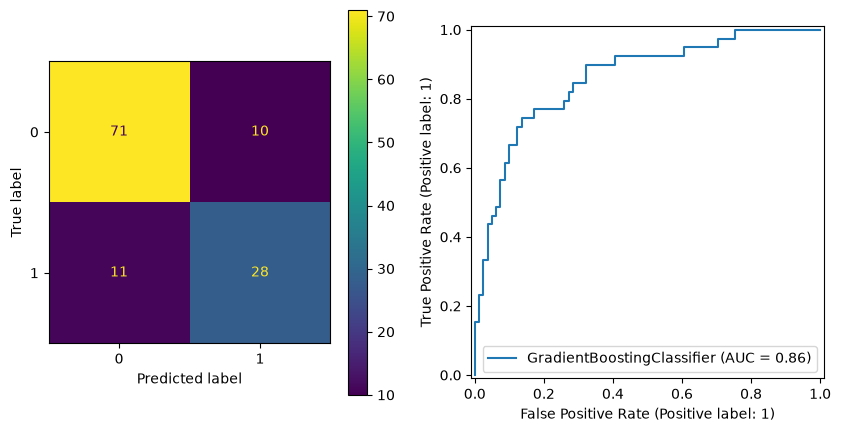

In [48]:
fig, ax = plt.subplots(1,2, figsize=(10, 5))
ConfusionMatrixDisplay.from_estimator(gb1, features_test, targets_test, ax=ax[0])
RocCurveDisplay.from_estimator(gb1, features_test, targets_test, ax=ax[1])

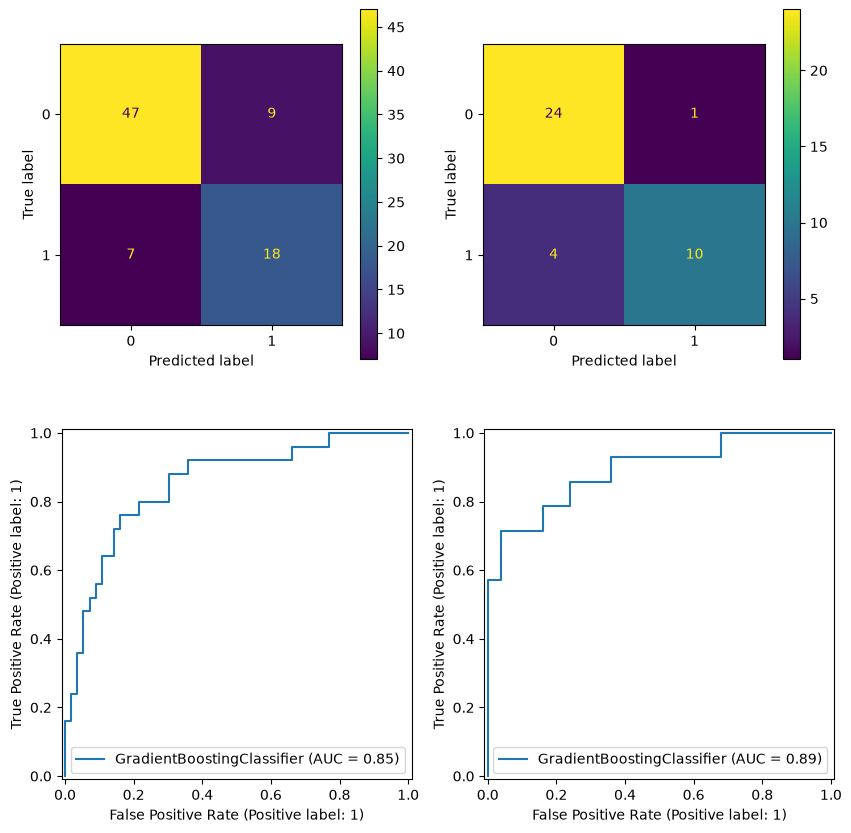

In [49]:
fig, ax = plt.subplots(2,2, figsize=(10, 10))
ConfusionMatrixDisplay.from_estimator(gb1, features_test_male, targets_test_male, ax=ax[0,0])
ConfusionMatrixDisplay.from_estimator(gb1, features_test_female, targets_test_female, ax=ax[0,1])
RocCurveDisplay.from_estimator(gb1, features_test_male, targets_test_male, ax=ax[1,0])
RocCurveDisplay.from_estimator(gb1, features_test_female, targets_test_female, ax=ax[1,1])

In [ ]:
tn_male, fp_male, fn_male, tp_male = confusion_matrix(targets_test_male, gb1.predict(features_test_male)).ravel()
tpr_male = tp_male/(tp_male+fn_male)
fpr_male = fp_male/(fp_male+tn_male)
ppv_male = tp_male/(tp_male+fp_male)
tn_female, fp_female, fn_female, tp_female = confusion_matrix(targets_test_female, gb1.predict(features_test_female)).ravel()
tpr_female = tp_female/(tp_female+fn_female)
fpr_female = fp_female/(fp_female+tn_female)
ppv_female = tp_female/(tp_female+fp_female)
print(f'TPR: Male {tpr_male:.3f} FEMALE {tpr_female:.3f}')
print(f'FPR: Male {fpr_male:.3f} FEMALE {fpr_female:.3f}')
print(f'PPV: Male {ppv_male:.3f} FEMALE {ppv_female:.3f}')


TPR: Male 0.72 FEMALE 0.71
FPR: Male 0.16 FEMALE 0.04
PPV: Male 0.67 FEMALE 0.91
